# 03 · Customer segmentation: RFM + K-Means

**Goal:** split the customer base into a few groups that each warrant a **different action**, with sizes and revenue shares the CRM team can plan around.

**Method:**
1. Compute recency, frequency and monetary value per `customer_unique_id`, as of **2018-09-01**.
2. Transform: log for the skewed frequency and monetary values (frequency capped at 3), then standardise all three.
3. Run K-Means. Choose k from the **elbow**, the **silhouette** score and **business sense**.
4. Name the clusters with explicit rules based on their profile, and attach an action to each.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from olist.config import METRICS_DIR
from olist.plotting import INK_SECONDARY, SERIES, save, use_style
from olist.segmentation import (
    SEGMENT_ACTIONS,
    fit_kmeans,
    k_diagnostics,
    name_segments,
    rfm_table,
    transform,
)
from olist.warehouse import connect, order_facts, run_sql_file

use_style()
con = connect()
orders = order_facts(con)
AS_OF = "2018-09-01"
rfm = rfm_table(orders, AS_OF)
print(f"{len(rfm):,} customers as of {AS_OF}")
print(rfm[["recency_days", "frequency", "monetary"]].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(1))
print("\nOrders per customer:")
print(rfm.frequency.value_counts(normalize=True).sort_index().head(5).map("{:.2%}".format).to_string())

94,983 customers as of 2018-09-01
       recency_days  frequency  monetary
count       94983.0    94983.0   94983.0
mean          240.3        1.0     165.7
std           153.0        0.2     226.8
min             2.0        1.0       9.6
25%           116.0        1.0      63.1
50%           221.0        1.0     107.9
75%           349.0        1.0     183.0
90%           469.0        1.0     319.0
99%           577.0        2.0    1099.5
max           726.0       16.0   13664.1

Orders per customer:
frequency
1    96.96%
2     2.79%
3     0.20%
4     0.03%
5     0.01%


**Frequency is almost constant.** About 97% of customers have exactly one order, so frequency splits off only a small group of repeat buyers. Recency and monetary value do most of the work, which is why the transform caps frequency at 3 and log-scales it rather than giving it equal weight in raw form.

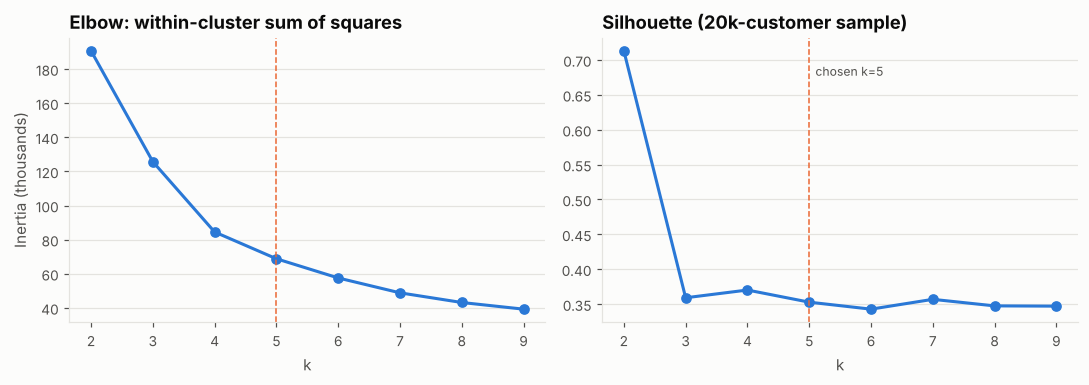

,k,inertia,silhouette,smallest_cluster_share
0,2,190671.299,0.713,0.03
1,3,125690.032,0.359,0.03
2,4,84493.783,0.370,0.03
3,5,68800.625,0.353,0.03
4,6,57551.374,0.343,0.03
5,7,48830.929,0.357,0.03
6,8,43165.809,0.347,0.03
7,9,39264.306,0.347,0.03


In [2]:
X = transform(rfm)
diag = k_diagnostics(X, range(2, 10), sample=20_000)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(diag.k, diag.inertia / 1e3, marker="o", color=SERIES[0])
axes[0].set_title("Elbow: within-cluster sum of squares")
axes[0].set_ylabel("Inertia (thousands)")
axes[1].plot(diag.k, diag.silhouette, marker="o", color=SERIES[0])
axes[1].set_title("Silhouette (20k-customer sample)")
for a in axes:
    a.set_xlabel("k")
    a.axvline(5, color=SERIES[1], linestyle="--", linewidth=1)
axes[1].text(5.1, diag.silhouette.max() * 0.95, "chosen k=5", color=INK_SECONDARY, fontsize=8)
plt.tight_layout()
save(fig, "kmeans_k_choice")
plt.show()
diag.round(3)

**Choosing k = 5.**
- **Silhouette** peaks at k = 2 (0.71). That solution just separates repeat buyers (3%) from everyone else, which we already know from SQL and which suggests no action.
- From k = 3 to 8 the silhouette stays flat at about 0.34–0.37, and the **elbow** bends around k = 4–5. Inertia drops 33% from k = 3 to 4, 19% from 4 to 5 and 16% from 5 to 6.
- **Business sense breaks the tie.** k = 4 has the best silhouette in the plateau (0.370), but k = 5 (0.353) splits the big one-time spenders into **recent** and **lapsed** groups. These need opposite actions: a second-order nudge now, or a win-back offer. k = 6 only splits the low spenders again without a new action.

In [3]:
km = fit_kmeans(X, 5)
rfm["cluster"] = km.labels_
profile = rfm.groupby("cluster").agg(
    customers=("customer_unique_id", "size"),
    recency_days=("recency_days", "mean"),
    frequency=("frequency", "mean"),
    monetary=("monetary", "mean"),
    median_monetary=("monetary", "median"),
    avg_review=("avg_review", "mean"),
    revenue=("monetary", "sum"),
)
names = name_segments(profile)
profile["segment"] = profile.index.map(names)
profile["customer_share"] = profile.customers / profile.customers.sum()
profile["revenue_share"] = profile.revenue / profile.revenue.sum()
profile["action"] = profile.segment.map(SEGMENT_ACTIONS)
profile = profile.sort_values("revenue_share", ascending=False)
rfm["segment"] = rfm.cluster.map(names)
pd.set_option("display.max_colwidth", 120)
profile[["segment", "customers", "customer_share", "revenue_share", "recency_days", "frequency", "monetary", "median_monetary", "avg_review"]].round(3)

,segment,customers,customer_share,revenue_share,recency_days,frequency,monetary,median_monetary,avg_review
cluster,,,,,,,,,
0,At-risk big spenders,11781,0.124,0.386,297.851,1.000,515.449,367.20,3.952
2,Recent mid-value buyers,29664,0.312,0.314,133.084,1.000,166.647,147.78,4.077
4,"One-and-done (lapsed, low value)",24810,0.261,0.155,426.164,1.000,98.036,88.08,4.180
1,Recent low-value buyers,25842,0.272,0.089,160.695,1.000,54.222,53.90,4.161
3,Champions,2886,0.030,0.057,223.524,2.114,308.610,225.53,4.168


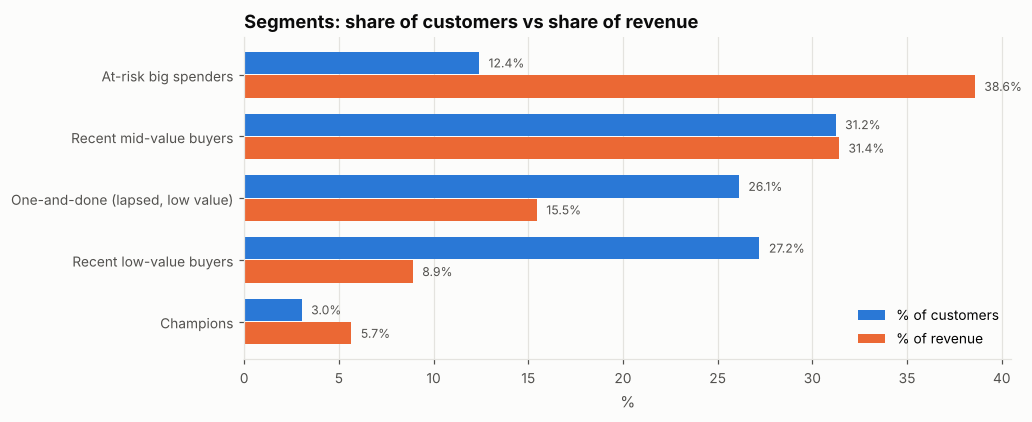

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(profile))[::-1]
ax.barh(y + 0.19, profile.customer_share * 100, height=0.36, color=SERIES[0], label="% of customers")
ax.barh(y - 0.19, profile.revenue_share * 100, height=0.36, color=SERIES[1], label="% of revenue")
for yi, c, r in zip(y, profile.customer_share, profile.revenue_share):
    ax.text(c * 100 + 0.5, yi + 0.19, f"{c:.1%}", va="center", fontsize=8, color=INK_SECONDARY)
    ax.text(r * 100 + 0.5, yi - 0.19, f"{r:.1%}", va="center", fontsize=8, color=INK_SECONDARY)
ax.set_yticks(y, profile.segment)
ax.set_xlabel("%")
ax.set_title("Segments: share of customers vs share of revenue")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
save(fig, "segments")
plt.show()

### Segment playbook
The table below is generated from the fitted clusters. Names come from the rules in `olist.segmentation.name_segments`: the highest-frequency cluster is "Champions", and the rest are split by whether their mean recency and monetary value are above or below the median across clusters.

In [5]:
playbook = profile[["segment", "customers", "customer_share", "revenue_share", "recency_days", "monetary", "action"]].copy()
playbook["customer_share"] = playbook.customer_share.map("{:.1%}".format)
playbook["revenue_share"] = playbook.revenue_share.map("{:.1%}".format)
playbook["recency_days"] = playbook.recency_days.round(0).astype(int)
playbook["monetary"] = playbook.monetary.map("R$ {:,.0f}".format)
playbook.reset_index(drop=True)

,segment,customers,customer_share,revenue_share,recency_days,monetary,action
0,At-risk big spenders,11781,12.4%,38.6%,298,R$ 515,"Personal win-back offer on the category they bought, before day 365."
1,Recent mid-value buyers,29664,31.2%,31.4%,133,R$ 167,Second-order nudge within 30-90 days: complementary-category bundle.
2,"One-and-done (lapsed, low value)",24810,26.1%,15.5%,426,R$ 98,Low-cost channels only (email/newsletter); do not pay to reacquire.
3,Recent low-value buyers,25842,27.2%,8.9%,161,R$ 54,"Cheap reactivation: free-shipping-threshold reminder, cross-sell."
4,Champions,2886,3.0%,5.7%,224,R$ 309,"VIP treatment: early access, loyalty points, referral asks. Protect, don't discount."


### Cross-check against the rule-based SQL RFM (query 03)
The SQL version scores R and M with `NTILE(5)` and names segments with fixed rules. If both methods find the same structure, the clusters are not an artefact of K-Means.

In [6]:
sql_rfm = run_sql_file(con, "03_rfm_scores")
sql_rfm[["segment", "customers", "customer_share", "revenue_share", "avg_recency_days", "avg_monetary"]].round(3)

,segment,customers,customer_share,revenue_share,avg_recency_days,avg_monetary
0,New big spenders,14643,0.154,0.282,94.652,303.083
1,At-risk big spenders,13998,0.147,0.275,397.818,309.244
2,Fading one-timers,18374,0.193,0.178,223.235,152.102
3,Lost one-timers,22967,0.242,0.106,399.203,72.791
4,New low spenders,22115,0.233,0.103,92.688,73.074
5,"Loyal, lapsing",1652,0.017,0.031,323.872,298.642
6,Champions,1234,0.013,0.025,91.524,321.956


**So what.**
- **At-risk big spenders** are **12.4% of customers but 38.6% of revenue**. They average **R\$ 515** (median R\$ 367) and last ordered about **298 days** ago. They also have the **lowest mean review of any segment (3.95)**, so a bad first experience may be part of why they have not returned. **Action:** a personal win-back offer in their original category, opened with an apology or credit if their order was late. This is the one segment where paid reactivation clearly pays.
- **Recent mid-value buyers** (31.2% of customers, **31.4% of revenue**, R\$ 167 average, about 133 days) are still inside the window in which second orders happen (EDA Q8: 83% within 180 days). **Action:** a second-order nudge between day 30 and day 90 with a bundle from a complementary category.
- **Champions** are the **3.0%** who have already bought more than once (2.11 orders on average, R\$ 309). They bring in **5.7% of revenue**. **Action:** loyalty perks and referral requests rather than discounts. They are also the positive class the churn model in notebook 04 learns from.
- **Recent low-value buyers** (27.2%) and **One-and-done (lapsed, low value)** (26.1%) make up **53.3% of customers but only 24.4% of revenue**. **Action:** low-cost channels only (email, free-shipping-threshold reminders). Paid reacquisition would not pay back.
- **The SQL NTILE rules agree.** They also find a lapsed, high-value one-time group: "At-risk big spenders", 14.7% of customers and 27.5% of revenue, about 398 days since the last order. Their repeat-buyer groups ("Champions" plus "Loyal, lapsing") likewise come to about 3% of customers. The segment structure holds under two independent methods.

In [7]:
METRICS_DIR.mkdir(parents=True, exist_ok=True)
out = profile[["segment", "customers", "customer_share", "revenue_share", "recency_days", "frequency", "monetary", "avg_review", "action"]]
(METRICS_DIR / "segments.json").write_text(json.dumps({"k": 5, "as_of": AS_OF, "diagnostics": diag.to_dict(orient="records"), "segments": out.to_dict(orient="records")}, indent=2, default=float))
con.close()